<a href="https://colab.research.google.com/github/sen-soumya/Optical-communication/blob/main/Laser%20source%20classification%20and%20cpr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Imports and Setup


In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

### 2. Optical Link Simulation and Dataset Generation


In [2]:
LASER_PROFILES = {
    0: {"name": "ECL (External Cavity)", "linewidth": 10e3},   # 10 kHz (Ultra-narrow)
    1: {"name": "DFB (Distributed Feedback)", "linewidth": 2e6}, # 2 MHz (Moderate)
    2: {"name": "Nano-Laser (Micro-cavity)", "linewidth": 45e6} # 45 MHz (Wide Phase Noise)
}

def generate_multi_laser_dataset(num_symbols_per_laser=5000, snr_db=18, symbol_rate_baud=32e9, window_size=15):
    X_list, Y_phase_list, Y_label_list = [], [], []
    half_win = window_size // 2

    # Base 16-QAM constellation geometry mapping
    points = np.array([-3, -1, 1, 3])
    x, y = np.meshgrid(points, points)
    constellation = (x + 1j * y) / np.sqrt(10)

    for label_idx, profile in LASER_PROFILES.items():
        lw = profile["linewidth"]

        # Generate core symbol payload
        random_indices = np.random.choice(16, num_symbols_per_laser)
        tx_symbols = constellation.flatten()[random_indices]

        # Add baseline AWGN channel noise
        snr_linear = 10 ** (snr_db / 10)
        noise = np.sqrt(1.0 / (2 * snr_linear)) * (
            np.random.normal(size=num_symbols_per_laser) + 1j * np.random.normal(size=num_symbols_per_laser)
        )
        rx_awgn = tx_symbols + noise

        # Inject Wiener Phase Noise
        t_s = 1.0 / symbol_rate_baud
        phase_variance = 2 * np.pi * lw * t_s
        phase_steps = np.random.normal(0, np.sqrt(phase_variance), num_symbols_per_laser)
        phase_noise = np.cumsum(phase_steps)
        rx_symbols = rx_awgn * np.exp(1j * phase_noise)

        # Extract sliding windows for model context input
        for i in range(half_win, num_symbols_per_laser - half_win):
            window = rx_symbols[i - half_win : i + half_win + 1]
            features = np.stack([np.real(window), np.imag(window)], axis=0)

            X_list.append(features)
            Y_phase_list.append(phase_noise[i])
            Y_label_list.append(label_idx)

    return (
        torch.tensor(np.array(X_list), dtype=torch.float32),
        torch.tensor(np.array(Y_phase_list), dtype=torch.float32).unsqueeze(1),
        torch.tensor(np.array(Y_label_list), dtype=torch.long)
    )

### 3. Multi-Task Deep Learning Receiver Architecture


In [3]:
class MultiTaskOpticalReceiverAI(nn.Module):
    def __init__(self, window_size=15, num_classes=3):
        super(MultiTaskOpticalReceiverAI, self).__init__()

        # Shared 1D-Conv Feature Extractor
        self.shared_conv = nn.Sequential(
            nn.Conv1d(in_channels=2, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Flatten()
        )

        flattened_dim = 64 * window_size

        # Head 1: Laser Classifier
        self.classifier_head = nn.Sequential(
            nn.Linear(flattened_dim, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )

        # Head 2: Phase Correction Regressor
        self.regression_head = nn.Sequential(
            nn.Linear(flattened_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        features = self.shared_conv(x)
        laser_logits = self.classifier_head(features)
        predicted_phase = self.regression_head(features)
        return laser_logits, predicted_phase

### 4. Training Pipeline
Generate training sets, construct the model, configure optimizer/loss objectives, and execute the backpropagation training loop.

In [4]:
print(" Simulating training and test datasets...")
X_train, Y_phase_train, Y_label_train = generate_multi_laser_dataset(num_symbols_per_laser=10000)
X_test, Y_phase_test, Y_label_test = generate_multi_laser_dataset(num_symbols_per_laser=2000)

train_loader = DataLoader(TensorDataset(X_train, Y_phase_train, Y_label_train), batch_size=128, shuffle=True)

# Initialization
model = MultiTaskOpticalReceiverAI()
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion_cls = nn.CrossEntropyLoss()
criterion_reg = nn.MSELoss()


model.train()
for epoch in range(12):
    total_epoch_loss = 0
    correct_laser_predictions = 0

    for batch_x, batch_phase, batch_label in train_loader:
        optimizer.zero_grad()

        logits, phase_pred = model(batch_x)

        # Multi-objective dynamic optimization loss
        loss_cls = criterion_cls(logits, batch_label)
        loss_reg = criterion_reg(phase_pred, batch_phase)
        total_loss = loss_reg + 0.4 * loss_cls

        total_loss.backward()
        optimizer.step()

        total_epoch_loss += total_loss.item()
        correct_laser_predictions += (torch.argmax(logits, dim=1) == batch_label).sum().item()

    accuracy = (correct_laser_predictions / len(X_train)) * 100
    print(f"Epoch {epoch+1:2d}/12 | Combined Loss: {total_epoch_loss:.4f} | Classifier Accuracy: {accuracy:.2f}%")

 Simulating training and test datasets...
Epoch  1/12 | Combined Loss: 5846.4737 | Classifier Accuracy: 33.78%
Epoch  2/12 | Combined Loss: 5676.9939 | Classifier Accuracy: 34.79%
Epoch  3/12 | Combined Loss: 5608.0061 | Classifier Accuracy: 37.52%
Epoch  4/12 | Combined Loss: 5420.9130 | Classifier Accuracy: 43.25%
Epoch  5/12 | Combined Loss: 4951.8863 | Classifier Accuracy: 49.39%
Epoch  6/12 | Combined Loss: 4467.4158 | Classifier Accuracy: 53.40%
Epoch  7/12 | Combined Loss: 4268.4586 | Classifier Accuracy: 55.07%
Epoch  8/12 | Combined Loss: 4009.7201 | Classifier Accuracy: 57.07%
Epoch  9/12 | Combined Loss: 3812.1311 | Classifier Accuracy: 57.73%
Epoch 10/12 | Combined Loss: 3595.0750 | Classifier Accuracy: 58.94%
Epoch 11/12 | Combined Loss: 3381.1739 | Classifier Accuracy: 60.10%
Epoch 12/12 | Combined Loss: 3123.0391 | Classifier Accuracy: 61.24%


### 5. Evaluation & Constellation Visualization



Independent Laser Performance Evaluation:
 ECL (External Cavity) Phase Extraction Precision MSE: 1.33542e+01 rad^2
 DFB (Distributed Feedback) Phase Extraction Precision MSE: 2.21692e+01 rad^2
 Nano-Laser (Micro-cavity) Phase Extraction Precision MSE: 3.49052e+01 rad^2


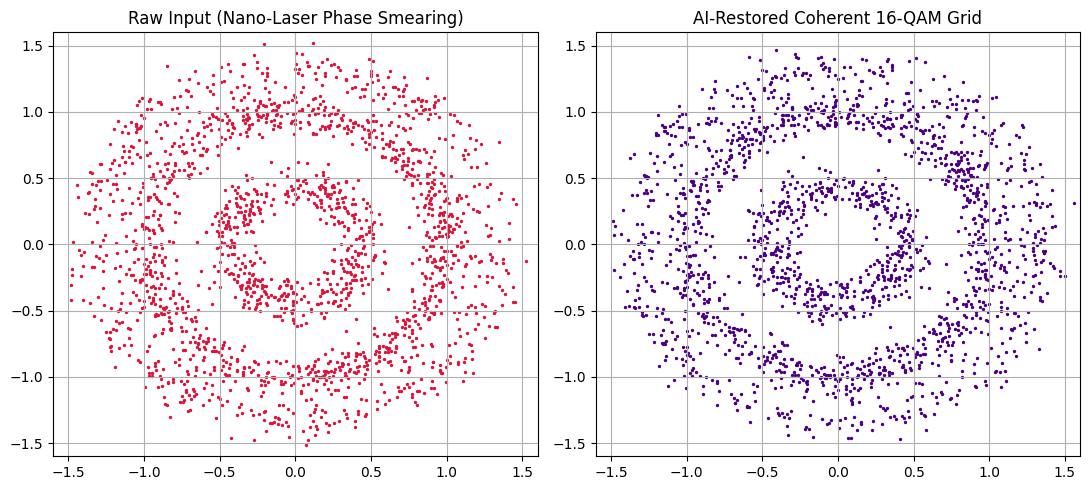

In [7]:
model.eval()
with torch.no_grad():
    test_logits, test_phase_preds = model(X_test)

test_phase_preds = test_phase_preds.numpy().flatten()
inferred_laser_types = torch.argmax(test_logits, dim=1).numpy()

print("\nIndependent Laser Performance Evaluation:")
for label_idx, profile in LASER_PROFILES.items():
    mask = (Y_label_test.numpy() == label_idx)
    mse_subset = np.mean((test_phase_preds[mask] - Y_phase_test.numpy().flatten()[mask]) ** 2)
    print(f" {profile['name']} Phase Extraction Precision MSE: {mse_subset:.5e} rad^2")

# Focus evaluation on the highly unstable Nano-Laser dataset
mask_nano = (Y_label_test.numpy() == 2)
X_nano = X_test.numpy()[mask_nano]

# Reconstruct standard QAM mapping
raw_received_nano = X_nano[:, 0, 7] + 1j * X_nano[:, 1, 7]
compensated_nano = raw_received_nano * np.exp(-1j * test_phase_preds[mask_nano])

# Render comparison charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

ax1.scatter(np.real(raw_received_nano), np.imag(raw_received_nano), s=2, color='crimson')
ax1.set_title("Raw Input (Nano-Laser Phase Smearing)")
ax1.set_xlim([-1.6, 1.6]); ax1.set_ylim([-1.6, 1.6]); ax1.grid(True)

ax2.scatter(np.real(compensated_nano), np.imag(compensated_nano), s=2, color='indigo')
ax2.set_title("AI-Restored Coherent 16-QAM Grid")
ax2.set_xlim([-1.6, 1.6]); ax2.set_ylim([-1.6, 1.6]); ax2.grid(True)

plt.tight_layout()
plt.show()